In [1]:
import numpy as np
from scipy.signal import find_peaks
from read_raw_data import read_dat_file
import matplotlib.pyplot as plt

def get_reference_signal(file_path, center_freq_rx, sample_rate, tx_freq, num_read_samples, nfft=2**15, start_from=None):
    # Load the signal from the file
    start_index = None
    stop_index = None
    no_sig_count = 0
    num_read_samples = int(nfft)
    
    if start_from is None:
        idx = 0
    else:
        idx = int(start_from)

    # bin to look at for the tx freq
    tx_bin = round(((tx_freq-center_freq_rx) / (sample_rate / nfft))/2)
    print("tx_bin: ", tx_bin)
    while True:
        # read the signal from the file
        sig_seg = read_dat_file(file_path, num_read_samples, idx)
        if len(sig_seg) < num_read_samples:
            break
        # calc the fft
        sig_fft = np.fft.fft(sig_seg)
        # calc the power spectral density
        psd = np.abs(sig_fft) ** 2
        # find mean of the psd
        mean_psd = np.mean(psd)
        if psd[tx_bin] > mean_psd * 10:
            if start_index is None:
                start_index = idx
            else:
                stop_index = idx
        else:
            if stop_index is not None and start_index is not None:
                no_sig_count = no_sig_count + 1
                if no_sig_count > 5:
                    break   
        idx += num_read_samples
        # plot psd for debugging.
        # plt.cla() 
        # plt.plot(psd)
        # plt.pause(0.05)
    # plt.show()

    return start_index, stop_index

# Example usage:
file_path = "/home/ishani/LeoPNT/USRP_data/1_27/time_15_15_freq_11_325G_bw_2.0M_1706391792.6762946_inrx2.dat"
center_freq_rx = 11.325e9  # Replace with the actual center frequency of your receiver
sample_rate = 2e6  # Replace with the actual sample rate of your signal
tx_freq = 11.3252e9  # Replace with the actual transmit frequency
nfft = 2**15  # Replace with the fft size you want to use
num_read_samples = nfft  # Replace with the number of samples you want to read at a time
start_from = None

start_index, stop_index = get_reference_signal(file_path, center_freq_rx, sample_rate, tx_freq, num_read_samples, nfft, start_from)
print("Start Index:", start_index)
print("Stop Index:", stop_index)

tx_bin:  1638
Start Index: 13762560
Stop Index: 24739840


In [3]:
from read_raw_data import read_dat_file

# write a function called get reference signal that takes path to a file and gives you a start and stop index for the reference signal
# this function should take the center freq of rx as input and also the sample rate. it should also take tx frequency as input so it knows the bin to look for high power in. 
# when parsing the signal, when the power is high for first time, start index is set. when power is low for first time after start index is set, stop index is set.
# return start and stop index.

iq0_path = '/home/ishani/LeoPNT/USRP_data/1_27/time_15_15_freq_11_325G_bw_2.0M_1706391792.6762946_inrx0.dat'
iq1_path = '/home/ishani/LeoPNT/USRP_data/1_27/time_15_15_freq_11_325G_bw_2.0M_1706391792.6762946_inrx1.dat'
iq2_path = '/home/ishani/LeoPNT/USRP_data/1_27/time_15_15_freq_11_325G_bw_2.0M_1706391792.6762946_inrx2.dat'

iq0 = read_dat_file(iq0_path, None, None)
iq1 = read_dat_file(iq1_path, None, None)
iq2 = read_dat_file(iq2_path, None, None)

print(iq0.shape, iq1.shape, iq2.shape)

(401997232,) (401997232,) (401997232,)


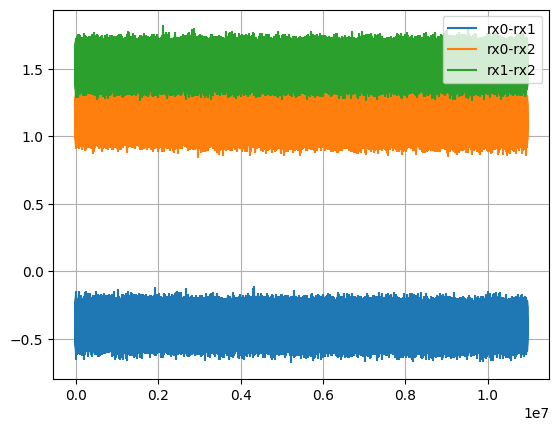

In [10]:
import numpy as np
from matplotlib import pyplot as plt
# Set a higher value for agg.path.chunksize
plt.rcParams['agg.path.chunksize'] = 200

file_path = iq0_path
center_freq_rx = 11.325e9  # Replace with the actual center frequency of your receiver
sample_rate = 2e6  # Replace with the actual sample rate of your signal
tx_freq = 11.3252e9  # Replace with the actual transmit frequency
nfft = 2**15  # Replace with the fft size you want to use
num_read_samples = nfft  # Replace with the number of samples you want to read at a time
start_from = None

while True:

    start_index, stop_index = get_reference_signal(file_path, center_freq_rx, sample_rate, tx_freq, num_read_samples, nfft, start_from)
    print("Start Index:", start_index)
    print("Stop Index:", stop_index)
    if start_index is None or stop_index is None:
        break   
    begin_index = int(start_index+2**15)
    end_index = int(stop_index-2**15)
    iq0_ = iq0[begin_index:end_index]
    iq1_ = iq1[begin_index:end_index]
    iq2_ = iq2[begin_index:end_index]
    # where iq is zero, replace with Nan
    # iq0_[np.where(iq0_ == 0)] = 10**-30
    iq1_[np.where(iq1_ == 0)] = 10**-30
    iq2_[np.where(iq2_ == 0)] = 10**-30

    del_phi_01 = np.unwrap(np.angle(iq0_/iq1_))
    del_phi_12 = np.unwrap(np.angle(iq1_/iq2_))
    del_phi_02 = np.unwrap(np.angle(iq0_/iq2_))

    plt.close('all')
    plt.plot(del_phi_01)
    plt.plot(del_phi_02)
    plt.plot(del_phi_12)
    # plt.ylim([-np.pi, np.pi])
    plt.legend(['rx0-rx1', 'rx0-rx2', 'rx1-rx2'], loc="upper right")
    plt.grid()
    plt.savefig('del_phi'+str(start_index)+'.png')